# Model 3 — Random Forest


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion, make_pipeline as sk_make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score, accuracy_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, get_scorer)
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from imblearn.pipeline import Pipeline          # imblearn Pipeline: resampling happens only on training folds
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 1. Load the train/test split and define the feature sets


In [2]:
train = pd.read_csv("../results/outputs/processed_dataset_train.csv")
test  = pd.read_csv("../results/outputs/processed_dataset_test.csv")
print("train:", train.shape, " test:", test.shape)

TARGET = "next_risk_class"
NON_FEATURES = ["patient_id", "timestamp", "date", "time", "code", "code_description",
                "risk_class",           # current band - circular with glucose_mg_dl
                "next_glucose",         # the next reading itself - would leak the answer
                "daily_total_insulin",  # whole-day total - includes insulin given AFTER this reading
                "reading_index",        # position in the patient's record - not physiology (see Section 8/10 evidence)
                TARGET]

PIPELINE_PCS = [c for c in train.columns if c.startswith("PC")]   # computed with the leaky column - not used
FEATURES = [c for c in train.columns if c not in NON_FEATURES and c not in PIPELINE_PCS]
print(f"{len(FEATURES)} clean input features (pipeline PC columns excluded: {len(PIPELINE_PCS)})")
print(FEATURES)

y_train, y_test = train[TARGET], test[TARGET]
groups_train = train["patient_id"]

print("\nClass distribution (train):")
print(y_train.value_counts(normalize=True).round(3))

train: (10635, 49)  test: (2659, 49)
21 clean input features (pipeline PC columns excluded: 17)
['hour', 'is_weekend', 'glucose_mg_dl', 'prev_glucose', 'hours_since_prev', 'rolling_mean_3', 'rolling_std_3', 'insulin_regular_6h', 'insulin_nph_6h', 'insulin_ultralente_6h', 'meals_6h', 'exercise_6h', 'hypo_symptoms_6h', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']

Class distribution (train):
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64


## 2. Why a Random Forest suits this problem


In [3]:
# Evidence for dropping daily_total_insulin: it has ONE value per patient per day, even on days with several
# readings - so a morning reading already "knows" the evening's doses.
per_day = train.groupby(["patient_id", "date"])["daily_total_insulin"].nunique()
readings = train.groupby(["patient_id", "date"]).size()
print("patient-days with a single daily_total_insulin value:", f"{(per_day == 1).mean():.1%}")
print("...of which have more than one reading that day     :", f"{(readings[per_day == 1] > 1).mean():.1%}")

patient-days with a single daily_total_insulin value: 100.0%
...of which have more than one reading that day     : 89.4%


## 3. Evaluation metrics

In [4]:
HYPO = "Hypoglycemic"

# Small wrappers score only the Hypoglycemic class. (Passing labels=... straight into make_scorer
# fails on string class names, because the scorer defaults to pos_label=1.)
def hypo_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_f2(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=2, labels=[HYPO], average="macro", zero_division=0)

scoring = {
    "balanced_acc":   "balanced_accuracy",
    "hypo_f2":        make_scorer(hypo_f2),
    "hypo_recall":    make_scorer(hypo_recall),
    "hypo_precision": make_scorer(hypo_precision),
    "macro_f1":       "f1_macro",
    "accuracy":       "accuracy",
    "roc_auc_ovr":    "roc_auc_ovr",   # macro one-vs-rest ROC AUC from predicted probabilities
}

def test_metrics(y_true, y_pred):
    return {
        "balanced_acc":   balanced_accuracy_score(y_true, y_pred),
        "hypo_recall":    hypo_recall(y_true, y_pred),
        "hypo_precision": hypo_precision(y_true, y_pred),
        "hypo_f2":        hypo_f2(y_true, y_pred),
        "accuracy":       accuracy_score(y_true, y_pred),
        "macro_f1":       f1_score(y_true, y_pred, average="macro"),
    }

**Why not tune on hypo F2 or hypo recall?** Two trivial "models" show the problem. Predicting *every* reading as
Hypoglycemic gets hypo-recall 1.0 and a high hypo-F2, while balanced accuracy gives both trivial models exactly
0.333. Section 5 compares this trivial hypo-F2 against every trained model.

In [5]:
trivial = pd.DataFrame([
    {"model": "always Hypoglycemic", **test_metrics(y_train, np.full(len(y_train), HYPO))},
    {"model": "always Normal",       **test_metrics(y_train, np.full(len(y_train), "Normal"))},
]).round(3)
TRIVIAL_HYPO_F2 = trivial.loc[0, "hypo_f2"]
print(trivial.to_string())

                 model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
0  always Hypoglycemic         0.333          1.0           0.116    0.396     0.116     0.069
1        always Normal         0.333          0.0           0.000    0.000     0.523     0.229


## 4. Hyperparameter tuning — GridSearchCV


In [6]:
# StandardScaler -> PCA(95% variance). imblearn does not allow a Pipeline as an intermediate step,
# so the block is wrapped in a FeatureUnion (which imblearn accepts).
def pca_block():
    return sk_make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=RANDOM_STATE))

FEATURE_OPTIONS = {
    "original": "passthrough",
    "pca":      FeatureUnion([("pcs", pca_block())]),
    "all":      FeatureUnion([("original", "passthrough"), ("pcs", pca_block())]),
}

pipe = Pipeline([
    ("features", "passthrough"),
    ("sampler",  "passthrough"),
    ("clf",      RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=RANDOM_STATE)),
])

FOREST_GRID = {"clf__max_depth":        [4, 8, None],
               "clf__min_samples_leaf": [5, 30],
               "clf__max_features":     ["sqrt", 0.5]}
common = {"features": list(FEATURE_OPTIONS.values()), **FOREST_GRID}
param_grid = [
    {**common, "sampler": ["passthrough"], "clf__class_weight": [None, "balanced"]},
    {**common, "sampler": [SMOTE(random_state=RANDOM_STATE), RandomUnderSampler(random_state=RANDOM_STATE)],
     "clf__class_weight": [None]},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit="balanced_acc", cv=cv, n_jobs=-1,
                  return_train_score=True,   # training-fold scores, for the overfitting check
                  error_score="raise")       # fail loudly instead of silently returning NaN
gs.fit(train[FEATURES], y_train)

def feature_set_name(step):
    if isinstance(step, str): return "original"
    return "all" if len(step.transformer_list) == 2 else "pca"

cv_all = pd.DataFrame(gs.cv_results_)
cv_all["feature_set"] = cv_all["param_features"].apply(feature_set_name)
print(cv_all.groupby("feature_set")["mean_test_balanced_acc"].max().round(3).rename("best CV balanced acc"))
print("\nTotal configurations evaluated:", len(cv_all))

feature_set
all         0.518
original    0.520
pca         0.511
Name: best CV balanced acc, dtype: float64

Total configurations evaluated: 144


## 5. Comparison across varieties (cross-validation, training set)
Each row below is one **variety** = feature set × imbalance strategy, shown with its best `max_depth`,
`min_samples_leaf` and `max_features` (12 varieties, each tuned over 12 forest settings).

In [7]:
def strategy(sampler, class_weight):
    if isinstance(sampler, SMOTE): return "SMOTE"
    if isinstance(sampler, RandomUnderSampler): return "Undersampling"
    return "Class weights" if class_weight == "balanced" else "None"

cv_all["imbalance"] = [strategy(s, w) for s, w in zip(cv_all["param_sampler"], cv_all["param_clf__class_weight"])]
cv_all["depth"] = cv_all["param_clf__max_depth"].apply(lambda d: np.inf if pd.isna(d) else float(d))
cv_all["depth_label"] = cv_all["depth"].apply(lambda d: "unlimited" if np.isinf(d) else str(int(d)))
cv_all["leaf"] = cv_all["param_clf__min_samples_leaf"].astype(int)
cv_all["max_feat"] = cv_all["param_clf__max_features"].astype(str)

metric_cols = ["mean_test_balanced_acc", "std_test_balanced_acc", "mean_test_hypo_f2", "mean_test_hypo_recall",
               "mean_test_hypo_precision", "mean_test_macro_f1", "mean_test_accuracy", "mean_test_roc_auc_ovr"]
best_per_variety = (cv_all.sort_values("mean_test_balanced_acc", ascending=False)
                          .groupby(["feature_set", "imbalance"], as_index=False).first())
varieties = (best_per_variety[["feature_set", "imbalance", "depth_label", "leaf", "max_feat"] + metric_cols]
             .rename(columns=lambda c: c.replace("mean_test_", ""))
             .sort_values("balanced_acc", ascending=False).reset_index(drop=True))
print(f"{len(varieties)} varieties (each tuned over {cv_all.groupby(['feature_set', 'imbalance']).size().iloc[0]} forest settings)")
print(varieties.round(3).to_string())

12 varieties (each tuned over 12 forest settings)
   feature_set      imbalance depth_label  leaf max_feat  balanced_acc  std_test_balanced_acc  hypo_f2  hypo_recall  hypo_precision  macro_f1  accuracy  roc_auc_ovr
0     original          SMOTE   unlimited     5     sqrt         0.520                  0.010    0.342        0.362           0.282     0.508     0.568        0.718
1          all          SMOTE   unlimited     5     sqrt         0.518                  0.009    0.334        0.351           0.281     0.509     0.572        0.718
2     original  Undersampling   unlimited     5     sqrt         0.517                  0.008    0.418        0.543           0.217     0.467     0.497        0.696
3          all  Class weights   unlimited    30      0.5         0.516                  0.013    0.384        0.445           0.248     0.484     0.527        0.702
4     original  Class weights   unlimited     5     sqrt         0.515                  0.010    0.316        0.316          

In [8]:
# Effect of each choice, averaged over the other settings (best forest settings per variety)
# (the feature-set comparison uses only varieties that handle imbalance - the "None" rows would just drag
#  every average down equally)
cols_show = ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "macro_f1", "accuracy"]
handled = varieties[varieties.imbalance != "None"]
print(varieties.groupby("imbalance")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False).to_string(), "\n")
print(handled.groupby("feature_set")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False).to_string(), "\n")

print(f"Trivial 'always Hypoglycemic' hypo-F2 : {TRIVIAL_HYPO_F2:.3f}")
print(f"Best hypo-F2 of any trained model     : {cv_all['mean_test_hypo_f2'].max():.3f}")
print("-> tuning on hypo-F2 would have rewarded the trivial model over every real one"
      if TRIVIAL_HYPO_F2 > cv_all['mean_test_hypo_f2'].max() else
      "-> here the best trained model edges past the trivial one, but only just")

               balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  accuracy
imbalance                                                                            
SMOTE                 0.516        0.358           0.275    0.337     0.505     0.566
Class weights         0.513        0.402           0.271    0.361     0.491     0.541
Undersampling         0.512        0.545           0.216    0.418     0.462     0.492
None                  0.455        0.065           0.601    0.079     0.450     0.602 

             balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  accuracy
feature_set                                                                        
original            0.517        0.407           0.274    0.359     0.495     0.548
all                 0.516        0.450           0.248    0.380     0.485     0.530
pca                 0.509        0.448           0.240    0.377     0.478     0.522 

Trivial 'always Hypoglycemic' hypo-F2 : 0.396
Best hypo-F2 o

## 6. Choosing the final model 

In [9]:
N_FOLDS = cv.get_n_splits()
cv_all["se_bal"] = cv_all["std_test_balanced_acc"] / np.sqrt(N_FOLDS)
top = cv_all.loc[cv_all["mean_test_balanced_acc"].idxmax()]
threshold = top["mean_test_balanced_acc"] - top["se_bal"]

IMB_RANK = {"Class weights": 0, "Undersampling": 1, "SMOTE": 2, "None": 3}
FS_RANK  = {"original": 0, "pca": 1, "all": 2}
MF_RANK  = {"sqrt": 0, "0.5": 1}

tied = cv_all[cv_all["mean_test_balanced_acc"] >= threshold].copy()
tied["rank"] = list(zip(tied.imbalance.map(IMB_RANK), tied.feature_set.map(FS_RANK), tied.depth, -tied.leaf,
                        tied.max_feat.map(MF_RANK), -tied.mean_test_balanced_acc))
chosen = tied.sort_values("rank").iloc[0]

def describe(r):
    return (f"{r.feature_set} features, {r.imbalance}, max_depth={r.depth_label}, "
            f"min_samples_leaf={r.leaf}, max_features={r.max_feat}, 100 trees")

print(f"Highest CV balanced acc : {top.mean_test_balanced_acc:.4f}  ({describe(top)})")
print(f"One-SE threshold        : {threshold:.4f}   -> {len(tied)} of {len(cv_all)} configurations within one standard error of the best")
print(f"Chosen (first by preference)  : {chosen.mean_test_balanced_acc:.4f} ± {chosen.std_test_balanced_acc:.4f}  ({describe(chosen)})")

print("\nTied configurations by max_depth:")
print(tied.groupby("depth_label").size().reindex(["4", "8", "unlimited"]).dropna().astype(int).to_string())
chosen_params = cv_all.loc[chosen.name, "params"]

Highest CV balanced acc : 0.5199  (original features, SMOTE, max_depth=unlimited, min_samples_leaf=5, max_features=sqrt, 100 trees)
One-SE threshold        : 0.5153   -> 7 of 144 configurations within one standard error of the best
Chosen (first by preference)  : 0.5158 ± 0.0126  (all features, Class weights, max_depth=unlimited, min_samples_leaf=30, max_features=0.5, 100 trees)

Tied configurations by max_depth:
depth_label
8            1
unlimited    6


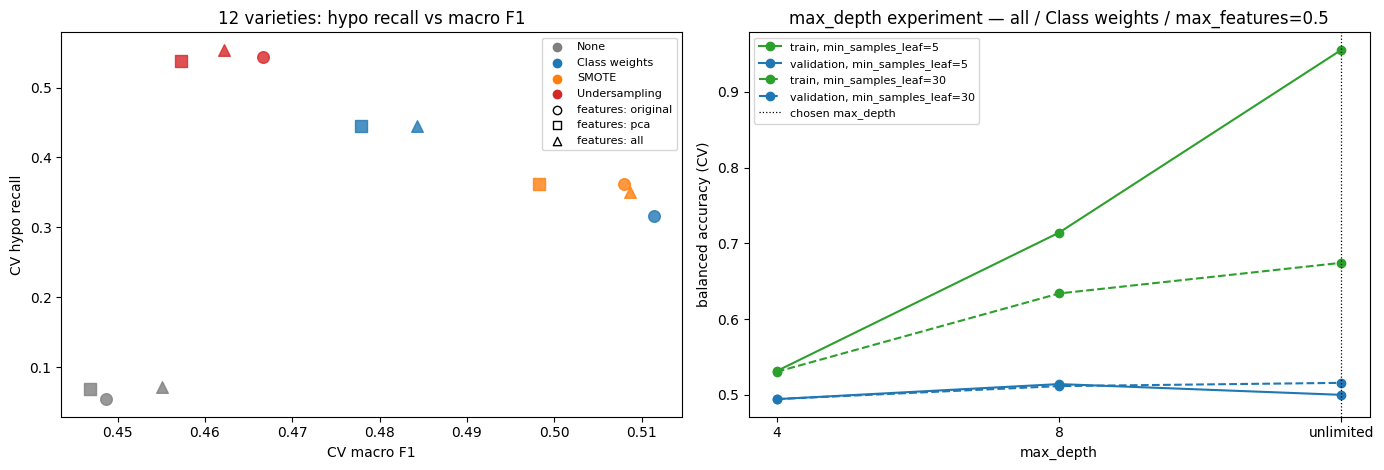

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) hypo-recall vs macro-F1 for every variety - the trade-off the imbalance strategies create
markers = {"original": "o", "pca": "s", "all": "^"}
colors = {"None": "tab:gray", "Class weights": "tab:blue", "SMOTE": "tab:orange", "Undersampling": "tab:red"}
for _, r in varieties.iterrows():
    axes[0].scatter(r.macro_f1, r.hypo_recall, marker=markers[r.feature_set], color=colors[r.imbalance],
                    s=70, alpha=0.8)
for k, c in colors.items():
    axes[0].scatter([], [], color=c, label=k)
for k, m in markers.items():
    axes[0].scatter([], [], marker=m, color="white", edgecolor="black", label=f"features: {k}")
axes[0].set_xlabel("CV macro F1"); axes[0].set_ylabel("CV hypo recall")
axes[0].set_title(f"{len(varieties)} varieties: hypo recall vs macro F1")
axes[0].legend(fontsize=8, loc="best")

# (b) max_depth experiment: train vs validation balanced accuracy, chosen feature set / imbalance / max_features
DEPTHS = ["4", "8", "unlimited"]
base = cv_all[(cv_all.feature_set == chosen.feature_set) & (cv_all.imbalance == chosen.imbalance) &
              (cv_all.max_feat == chosen.max_feat)]
for leaf, style in [(5, "-"), (30, "--")]:
    sub = base[base.leaf == leaf].set_index("depth_label").reindex(DEPTHS)
    x = range(len(DEPTHS))
    axes[1].plot(x, sub.mean_train_balanced_acc, style, marker="o", color="tab:green", label=f"train, min_samples_leaf={leaf}")
    axes[1].plot(x, sub.mean_test_balanced_acc, style, marker="o", color="tab:blue", label=f"validation, min_samples_leaf={leaf}")
axes[1].axvline(DEPTHS.index(chosen.depth_label), color="black", ls=":", lw=0.9, label="chosen max_depth")
axes[1].set_xticks(range(len(DEPTHS))); axes[1].set_xticklabels(DEPTHS)
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("balanced accuracy (CV)")
axes[1].set_title(f"max_depth experiment — {chosen.feature_set} / {chosen.imbalance} / max_features={chosen.max_feat}")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### How many trees? 
More trees never make a forest overfit more; they only make its average more stable, with diminishing returns. The
chosen configuration is re-scored with 10 to 500 trees (same 5 folds). If the validation curve is flat by 100 trees,
the 100 used in the grid is enough.

 trees  train  validation  validation std
    10 0.6478      0.4936          0.0065
    25 0.6648      0.5094          0.0095
    50 0.6714      0.5130          0.0120
   100 0.6743      0.5158          0.0126
   200 0.6747      0.5162          0.0121
   300 0.6773      0.5192          0.0108
   500 0.6778      0.5187          0.0103


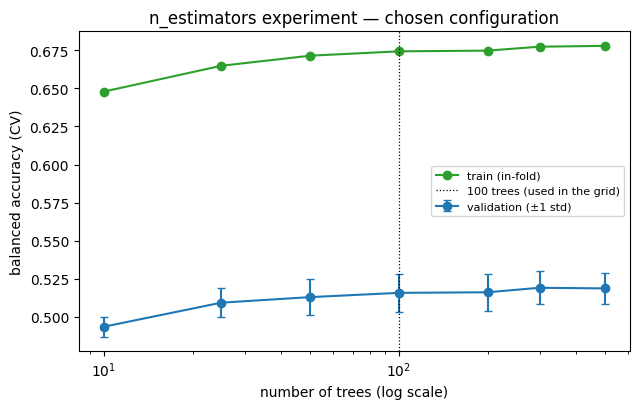

In [11]:
TREE_COUNTS = [10, 25, 50, 100, 200, 300, 500]
rows = []
for n in TREE_COUNTS:
    m = clone(pipe).set_params(**{**chosen_params, "clf__n_estimators": n})
    r = cross_validate(m, train[FEATURES], y_train, cv=cv, scoring="balanced_accuracy", return_train_score=True, n_jobs=-1)
    rows.append({"trees": n, "train": r["train_score"].mean(), "validation": r["test_score"].mean(),
                 "validation std": r["test_score"].std()})
trees_curve = pd.DataFrame(rows)
print(trees_curve.round(4).to_string(index=False))

plt.figure(figsize=(6.5, 4.2))
plt.plot(trees_curve.trees, trees_curve.train, marker="o", color="tab:green", label="train (in-fold)")
plt.errorbar(trees_curve.trees, trees_curve.validation, yerr=trees_curve["validation std"], marker="o",
             color="tab:blue", capsize=3, label="validation (±1 std)")
plt.axvline(100, color="black", ls=":", lw=0.9, label="100 trees (used in the grid)")
plt.xscale("log"); plt.xlabel("number of trees (log scale)"); plt.ylabel("balanced accuracy (CV)")
plt.title("n_estimators experiment — chosen configuration"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Final model — refit on the full training set, evaluated once on the test set
The chosen configuration is rebuilt from its parameters, refit on all training rows, and evaluated on the test set.

Final model: all features, Class weights, max_depth=unlimited, min_samples_leaf=30, max_features=0.5, 100 trees
Fitted forest: 100 trees, average depth = 15.2, average leaves per tree = 172

               precision    recall  f1-score   support

Hyperglycemic      0.502     0.611     0.551       960
 Hypoglycemic      0.234     0.416     0.300       308
       Normal      0.711     0.482     0.575      1391

     accuracy                          0.521      2659
    macro avg      0.482     0.503     0.475      2659
 weighted avg      0.580     0.521     0.534      2659



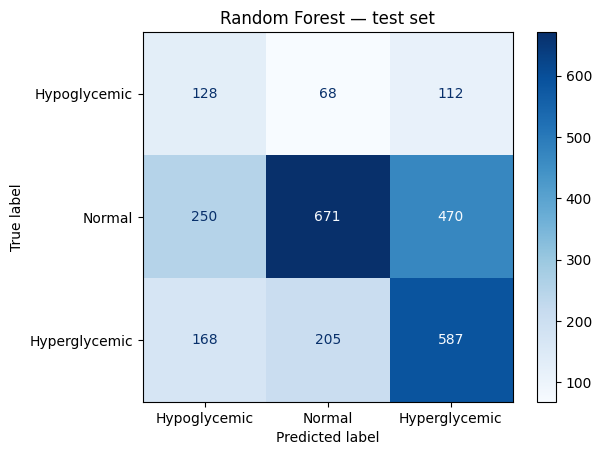

In [12]:
final_model = clone(pipe).set_params(**chosen_params).fit(train[FEATURES], y_train)
forest = final_model.named_steps["clf"]
mean_depth = np.mean([t.get_depth() for t in forest.estimators_])
mean_leaves = np.mean([t.get_n_leaves() for t in forest.estimators_])
print("Final model:", describe(chosen))
print(f"Fitted forest: {len(forest.estimators_)} trees, average depth = {mean_depth:.1f}, average leaves per tree = {mean_leaves:.0f}")

y_pred = final_model.predict(test[FEATURES])
print("\n" + classification_report(y_test, y_pred, digits=3))

LABELS = ["Hypoglycemic", "Normal", "Hyperglycemic"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS), display_labels=LABELS).plot(cmap="Blues")
plt.title("Random Forest — test set"); plt.show()

In [13]:
final_row = {"model": "Random Forest (tuned, chosen)", **test_metrics(y_test, y_pred)}

# Untuned forest: scikit-learn defaults (100 fully grown trees), same 21 features, no imbalance handling
default_forest = RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=RANDOM_STATE).fit(train[FEATURES], y_train)
default_row = {"model": "Random Forest (untuned defaults)", **test_metrics(y_test, default_forest.predict(test[FEATURES]))}

rows = [default_row, final_row]
for label, path in [("Decision Tree (Model 2, tuned)", "model_results_decision_tree.csv"),
                    ("Logistic Regression (Model 1, tuned)", "model_results_logistic_regression.csv")]:
    try:   # saved by the Model 1 / Model 2 notebooks: same features, same protocol, same test set
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"model": label, **{m: saved[m] for m in ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]}})
    except FileNotFoundError:
        print(f"({path} not found - run that notebook to add its row to this table.)")

comparison = pd.DataFrame(rows)
print(comparison[["model", "balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]]
      .round(3).to_string(index=False))

                               model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
    Random Forest (untuned defaults)         0.483        0.140           0.606    0.165     0.612     0.493
       Random Forest (tuned, chosen)         0.503        0.416           0.234    0.360     0.521     0.475
      Decision Tree (Model 2, tuned)         0.485        0.565           0.180    0.396     0.449     0.428
Logistic Regression (Model 1, tuned)         0.478        0.519           0.182    0.379     0.461     0.433


In [14]:
# What the hypo precision means in practice on the test set
n_alarms = int((y_pred == HYPO).sum())
n_true = int(((y_pred == HYPO) & (y_test == HYPO)).sum())
base_rate = (y_test == HYPO).mean()
alarm = {
    "hypo alarms raised":             n_alarms,
    "share of all readings flagged":  f"{n_alarms / len(y_test):.1%}",
    "real hypo events caught":        f"{n_true} of {int((y_test == HYPO).sum())}",
    "false alarms per real hypo":     f"{(n_alarms - n_true) / max(n_true, 1):.1f}",
    "precision vs base rate (lift)":  f"{(n_true / max(n_alarms, 1)) / base_rate:.2f}x",
}
print(pd.Series(alarm, name="value").to_frame().to_string())

                                    value
hypo alarms raised                    546
share of all readings flagged       20.5%
real hypo events caught        128 of 308
false alarms per real hypo            3.3
precision vs base rate (lift)       2.02x


### Comparing operating points — hypo recall at the same share of flagged readings
Hypo recall depends on how many readings a model chooses to flag, so a model that flags fewer readings can show lower
recall even when it ranks readings better. To compare like with like, the forest's hypo probabilities are ranked and the
top share of readings is flagged, matching the share flagged by each earlier model at its own default rule. (The test
labels are used only to measure recall at flag rates fixed by the other models; nothing is tuned on the test set.)

In [15]:
proba = final_model.predict_proba(test[FEATURES])
classes = list(final_model.named_steps["clf"].classes_)
p_hypo = proba[:, classes.index(HYPO)]
is_hypo = (y_test == HYPO).values

def forest_recall_at(share):
    k = int(round(share * len(y_test)))
    return is_hypo[np.argsort(-p_hypo)[:k]].sum() / is_hypo.sum()

rows = [{"compared with": "Random Forest itself (sanity check)", "share flagged": n_alarms / len(y_test),
         "that model's hypo recall": final_row["hypo_recall"],
         "forest hypo recall at that share": forest_recall_at(n_alarms / len(y_test))}]
for label, path in [("Decision Tree (Model 2)", "model_results_decision_tree.csv"),
                    ("Logistic Regression (Model 1)", "model_results_logistic_regression.csv")]:
    try:
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"compared with": label, "share flagged": saved["test_flagged_share"],
                     "that model's hypo recall": saved["hypo_recall"],
                     "forest hypo recall at that share": forest_recall_at(saved["test_flagged_share"])})
    except (FileNotFoundError, KeyError):
        print(f"({path} not found or lacks test_flagged_share - re-run that notebook to add its row.)")
matched = pd.DataFrame(rows)
print(matched.round(3).to_string(index=False))

                      compared with  share flagged  that model's hypo recall  forest hypo recall at that share
Random Forest itself (sanity check)          0.205                     0.416                             0.422
            Decision Tree (Model 2)          0.364                     0.565                             0.646
      Logistic Regression (Model 1)          0.330                     0.519                             0.594


### ROC AUC — ranking quality, independent of the threshold
Precision and recall above depend on the default rule "predict the class with the highest averaged probability". ROC
AUC instead asks how well the predicted probabilities *rank* readings. A forest averages many trees, so it can output
far more distinct scores than a single tree, and its ROC curve is smoother. Each curve is one class against the other
two.

Test ROC AUC - Hypoglycemic vs rest : 0.716
Test ROC AUC - macro one-vs-rest    : 0.701
Distinct hypo probability values the forest outputs: 2632


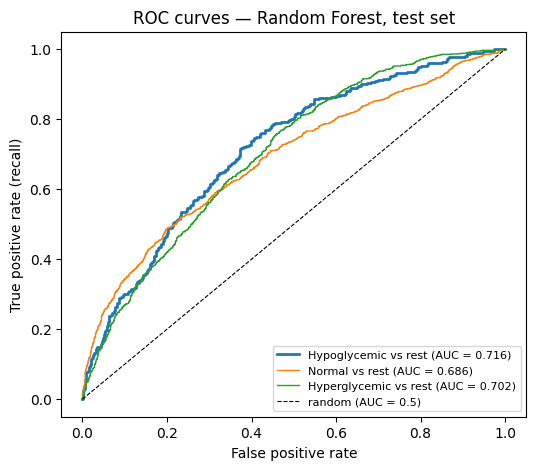

In [16]:
proba = final_model.predict_proba(test[FEATURES])
classes = list(final_model.named_steps["clf"].classes_)
hypo_auc  = roc_auc_score((y_test == HYPO).astype(int), proba[:, classes.index(HYPO)])
macro_auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=classes)
print(f"Test ROC AUC - Hypoglycemic vs rest : {hypo_auc:.3f}")
print(f"Test ROC AUC - macro one-vs-rest    : {macro_auc:.3f}")
print(f"Distinct hypo probability values the forest outputs: {len(np.unique(proba[:, classes.index(HYPO)]))}")

plt.figure(figsize=(6, 5))
for c in LABELS:
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), proba[:, classes.index(c)])
    auc_c = roc_auc_score((y_test == c).astype(int), proba[:, classes.index(c)])
    plt.plot(fpr, tpr, label=f"{c} vs rest (AUC = {auc_c:.3f})", lw=2 if c == HYPO else 1)
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves — Random Forest, test set"); plt.legend(fontsize=8); plt.show()

### Choosing the hypo alarm threshold on training data
The default rule (predict the class with the highest probability or score) is not tuned for catching hypo events. Here the
alarm threshold is chosen from **out-of-fold** hypo scores on the **training set only** — the test set plays no part in
choosing it — for three recall targets, and each resulting rule is applied to the test set once. Which recall level is
acceptable is a clinical decision; the targets only show the trade-off between caught hypo events and false alarms.

In [17]:
score_method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"
hypo_col = list(final_model.classes_).index(HYPO)
oof_scores = cross_val_predict(clone(final_model), train[FEATURES], y_train, cv=cv, method=score_method)[:, hypo_col]
test_hypo_scores = getattr(final_model, score_method)(test[FEATURES])[:, hypo_col]
oof_is_hypo = (y_train == HYPO).values
test_is_hypo = (y_test == HYPO).values

default_flag = (y_pred == HYPO)
rows = [{"rule": "default (highest score wins)", "threshold": np.nan,
         "test hypo recall": test_is_hypo[default_flag].sum() / test_is_hypo.sum(),
         "test hypo precision": test_is_hypo[default_flag].sum() / max(default_flag.sum(), 1),
         "test share flagged": default_flag.mean()}]
order = np.argsort(-oof_scores)
cum_recall = np.cumsum(oof_is_hypo[order]) / oof_is_hypo.sum()
for target in [0.5, 0.6, 0.7]:
    tau = oof_scores[order][np.searchsorted(cum_recall, target)]
    flag = test_hypo_scores >= tau
    rows.append({"rule": f"threshold for out-of-fold recall {target}", "threshold": tau,
                 "test hypo recall": test_is_hypo[flag].sum() / test_is_hypo.sum(),
                 "test hypo precision": test_is_hypo[flag].sum() / max(flag.sum(), 1),
                 "test share flagged": flag.mean()})
threshold_table = pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))
threshold_table.assign(model=final_row["model"]).to_csv(
    "../results/outputs/threshold_analysis_" + str(final_row["model"]).split()[0].lower() + ".csv", index=False)

                                rule  threshold  test hypo recall  test hypo precision  test share flagged
        default (highest score wins)        NaN             0.416                0.234               0.205
threshold for out-of-fold recall 0.5      0.353             0.490                0.240               0.237
threshold for out-of-fold recall 0.6      0.308             0.604                0.210               0.333
threshold for out-of-fold recall 0.7      0.270             0.721                0.199               0.420


## 8. Inside the forest — feature importance


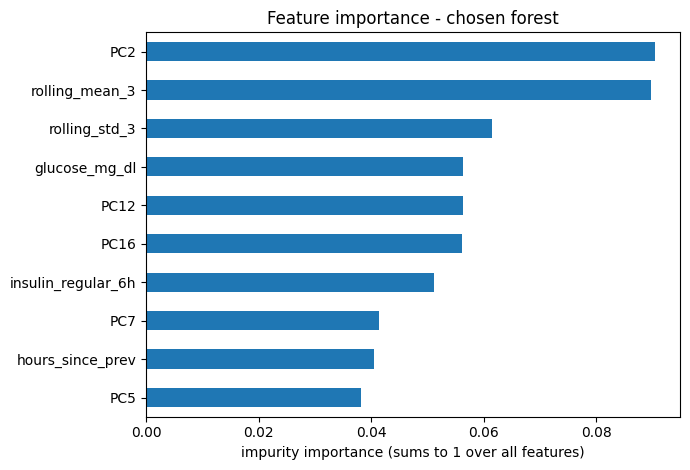

PC2                   0.090
rolling_mean_3        0.090
rolling_std_3         0.061
glucose_mg_dl         0.056
PC12                  0.056
PC16                  0.056
insulin_regular_6h    0.051
PC7                   0.041
hours_since_prev      0.041
PC5                   0.038

Features with importance above 0.02: 24 of 37


In [18]:
def feature_names(model):
    fs = feature_set_name(model.named_steps["features"])
    if fs == "original":
        return FEATURES
    n_pc = model.named_steps["features"].transformer_list[-1][1].named_steps["pca"].n_components_
    pcs = [f"PC{i + 1}" for i in range(n_pc)]
    return pcs if fs == "pca" else FEATURES + pcs

names = feature_names(final_model)
imp = pd.Series(forest.feature_importances_, index=names).sort_values(ascending=False)
top_imp = imp.head(10)
top_imp[::-1].plot.barh(figsize=(7, 4.8), color="tab:blue")
plt.xlabel("impurity importance (sums to 1 over all features)"); plt.title("Feature importance - chosen forest")
plt.tight_layout(); plt.show()
print(top_imp.round(3).to_string())
print(f"\nFeatures with importance above 0.02: {int((imp > 0.02).sum())} of {len(imp)}")

**`reading_index` is excluded from the features.** It is the reading's position in that patient's record (scaled), not a
physiological measurement. Pooled over patients, the hypo share can look as if it falls late in a record, but the two
tables below separate that pattern into its parts: **within** a patient's own record the hypo share barely moves, while
**between** patients it differs clearly, and the highest values of `reading_index` occur only in the patients with the
longest records. The feature therefore partly identifies *which patient* a reading comes from. In time-ordered validation
a patient's later readings receive larger `reading_index` values than any of their earlier ones, so a model that has
learned "large index = lower hypo risk" from the between-patient pattern is most consistent with under-predicting hypo on
future readings. In a separate audit on the training set, removing the feature raised time-ordered hypo recall at each of
three time cut points for each of the five models trained before KNN (15 of 15 comparisons), so it is excluded for all
six models. The sensitivity check at the end of Section 10 adds it back to this model.

In [19]:
ordered_ev = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
n_ev = ordered_ev.groupby("patient_id")["patient_id"].transform("size")
ordered_ev["own_position"] = ordered_ev.groupby("patient_id").cumcount() / n_ev
ordered_ev["hypo_next"] = (ordered_ev[TARGET] == HYPO).astype(int)
ordered_ev["own_fifth"] = pd.cut(ordered_ev["own_position"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], right=False,
                                 labels=["1st", "2nd", "3rd", "4th", "5th"])
print("WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record")
print(ordered_ev.groupby("own_fifth", observed=True)["hypo_next"].mean().round(3).to_string())

per_patient = ordered_ev.groupby("patient_id").agg(readings=("hypo_next", "size"), hypo_share=("hypo_next", "mean"),
                                                   highest_index=("reading_index", "max"))
per_patient["record length"] = pd.qcut(per_patient["readings"], 3, labels=["short", "medium", "long"])
print("\nBETWEEN patients: by length of the patient's record")
print(per_patient.groupby("record length", observed=True).agg(
    patients=("readings", "size"), mean_readings=("readings", "mean"), hypo_share=("hypo_share", "mean"),
    mean_highest_reading_index=("highest_index", "mean")).round(3).to_string())

WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record
own_fifth
1st    0.125
2nd    0.122
3rd    0.123
4th    0.102
5th    0.108

BETWEEN patients: by length of the patient's record
               patients  mean_readings  hypo_share  mean_highest_reading_index
record length                                                                 
short                24         66.833       0.179                      -0.089
medium               23         98.000       0.128                       0.104
long                 23        294.652       0.121                       1.427


## 9. Overfitting check — training vs cross-validation vs test
A forest of fully grown trees still fits its own training data almost perfectly, because each tree can memorise the
readings it was trained on. What matters is how much the score falls on data the forest has not seen. Three scores are
compared for the chosen configuration:
- **Train (in-fold):** average score on the training folds during cross-validation (data the model was fit on).
- **CV (validation):** average score on the held-out folds.
- **Test:** the final model on the test set.

For a forest the in-fold training score is optimistic by construction — each tree was trained on about 63% of those very
readings — so the train-versus-CV gap overstates how much a forest overfits; the CV and test scores are the honest
ones. The same comparison is made for the **untuned** forest (scikit-learn defaults), to show what the tuning bought. For
reference, Model 1 (Logistic Regression) had a train-versus-CV gap of about 0.002 (it underfit) and the tuned Model 2
tree had a gap of about 0.06.

In [20]:
fit_rows = ["balanced_acc", "hypo_recall", "macro_f1", "roc_auc_ovr"]
test_scores = {**test_metrics(y_test, y_pred), "roc_auc_ovr": macro_auc}
overfit = pd.DataFrame({
    "Train (in-fold)":  {m: chosen[f"mean_train_{m}"] for m in fit_rows},
    "CV (validation)":  {m: chosen[f"mean_test_{m}"] for m in fit_rows},
    "Test":             {m: test_scores[m] for m in fit_rows},
})
overfit["train - CV gap"] = overfit["Train (in-fold)"] - overfit["CV (validation)"]
print("Chosen (tuned) forest:")
print(overfit.round(3).to_string())

# Untuned forest: same folds, same scorers
u = cross_validate(clone(default_forest), train[FEATURES], y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
default_test = {**test_metrics(y_test, default_forest.predict(test[FEATURES])),
                "roc_auc_ovr": roc_auc_score(y_test, default_forest.predict_proba(test[FEATURES]),
                                             multi_class="ovr", average="macro", labels=list(default_forest.classes_))}
overfit_default = pd.DataFrame({
    "Train (in-fold)":  {m: u[f"train_{m}"].mean() for m in fit_rows},
    "CV (validation)":  {m: u[f"test_{m}"].mean() for m in fit_rows},
    "Test":             {m: default_test[m] for m in fit_rows},
})
overfit_default["train - CV gap"] = overfit_default["Train (in-fold)"] - overfit_default["CV (validation)"]
print("\nUntuned forest (defaults):")
print(overfit_default.round(3).to_string())

Chosen (tuned) forest:
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc            0.674            0.516  0.503           0.158
hypo_recall             0.763            0.445  0.416           0.317
macro_f1                0.611            0.484  0.475           0.127
roc_auc_ovr             0.832            0.702  0.701           0.131

Untuned forest (defaults):
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc              1.0            0.486  0.483           0.514
hypo_recall               1.0            0.149  0.140           0.851
macro_f1                  1.0            0.497  0.493           0.503
roc_auc_ovr               1.0            0.730  0.739           0.270


## 10. Validation checks — does the row-wise split flatter the scores?
The split is row-wise, so all 70 patients appear in both train and test, and a patient's *later* readings can sit in
training while their *earlier* readings are validated. A model that memorises (like a forest of deep trees) is the kind
most likely to benefit from that. Two extra checks, both on the training set only, re-score the chosen configuration:


In [21]:
# (a) Time-ordered: each patient's first 80% of readings train, last 20% validate
ordered = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
position = ordered.groupby("patient_id").cumcount()
n_readings = ordered.groupby("patient_id")["patient_id"].transform("size")
is_late = position >= np.floor(n_readings * 0.8)
early, late = ordered[~is_late], ordered[is_late]
print(f"Time-ordered split: {len(early)} earlier readings train / {len(late)} later readings validate "
      f"({late.patient_id.nunique()} patients in both)")
print(pd.DataFrame({"earlier 80%": early[TARGET].value_counts(normalize=True),
                    "later 20%":   late[TARGET].value_counts(normalize=True)}).round(3), "\n")

time_model = clone(final_model).fit(early[FEATURES], early[TARGET])
scorers = {m: (get_scorer(v) if isinstance(v, str) else v) for m, v in scoring.items()}
time_scores = {m: scorers[m](time_model, late[FEATURES], late[TARGET]) for m in scoring}

# (b) Unseen-patient generalisation check: GroupKFold, validation patients never seen in training
group_cv = cross_validate(clone(final_model), train[FEATURES], y_train, groups=groups_train,
                          cv=GroupKFold(n_splits=5), scoring=scoring, n_jobs=-1)

check = pd.DataFrame({
    "Row-wise CV (used for tuning)":     {m: chosen[f"mean_test_{m}"] for m in scoring},
    "Time-ordered (monitored patients)": time_scores,
    "GroupKFold (unseen patients)":      {m: group_cv[f"test_{m}"].mean() for m in scoring},
})
check["time-ordered - row-wise"] = check["Time-ordered (monitored patients)"] - check["Row-wise CV (used for tuning)"]
check["unseen patients - row-wise"] = check["GroupKFold (unseen patients)"] - check["Row-wise CV (used for tuning)"]
print(check.round(3).to_string())

Time-ordered split: 8477 earlier readings train / 2158 later readings validate (70 patients in both)
                 earlier 80%  later 20%
next_risk_class                        
Normal                 0.519      0.540
Hyperglycemic          0.363      0.351
Hypoglycemic           0.117      0.109 

                Row-wise CV (used for tuning)  Time-ordered (monitored patients)  GroupKFold (unseen patients)  time-ordered - row-wise  unseen patients - row-wise
balanced_acc                            0.516                              0.553                         0.486                    0.037                      -0.030
hypo_f2                                 0.384                              0.436                         0.354                    0.052                      -0.030
hypo_recall                             0.445                              0.519                         0.419                    0.074                      -0.026
hypo_precision                          0

### Which features carry the signal on future readings? — permutation importance
Impurity importance (Section 8) is computed on the training data. As a cross-check, the forest trained on each
patient's **earlier** readings is scored on their **later** readings, and each feature is shuffled in turn: the drop in
balanced accuracy shows how much the model depends on that feature for predicting the future. A drop near zero means
the feature is not needed for that prediction. The estimate is repeated 10 times per feature, and the standard
deviation shows how noisy it is. This uses only training-set rows, never the test set.

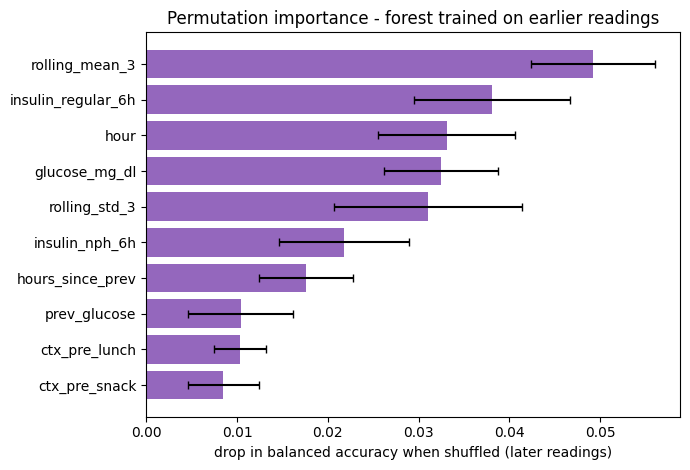

                    permutation drop     std
rolling_mean_3                0.0492  0.0068
insulin_regular_6h            0.0380  0.0086
hour                          0.0331  0.0075
glucose_mg_dl                 0.0324  0.0063
rolling_std_3                 0.0310  0.0104
insulin_nph_6h                0.0217  0.0072
hours_since_prev              0.0176  0.0052
prev_glucose                  0.0104  0.0058
ctx_pre_lunch                 0.0103  0.0028
ctx_pre_snack                 0.0085  0.0039

Top 5 by impurity importance   : PC2, rolling_mean_3, rolling_std_3, glucose_mg_dl, PC12
Top 5 by permutation importance: rolling_mean_3, insulin_regular_6h, hour, glucose_mg_dl, rolling_std_3


In [22]:
perm = permutation_importance(time_model, late[FEATURES], late[TARGET], scoring="balanced_accuracy",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_imp.index]
top_perm = perm_imp.head(10)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(range(len(top_perm))[::-1], top_perm.values, xerr=perm_std[top_perm.index].values, color="tab:purple", capsize=3)
ax.set_yticks(range(len(top_perm))[::-1]); ax.set_yticklabels(top_perm.index)
ax.set_xlabel("drop in balanced accuracy when shuffled (later readings)")
ax.set_title("Permutation importance - forest trained on earlier readings")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"permutation drop": top_perm.round(4), "std": perm_std[top_perm.index].round(4)}).to_string())
print("\nTop 5 by impurity importance   :", ", ".join(imp.head(5).index))
print("Top 5 by permutation importance:", ", ".join(perm_imp.head(5).index))

### Sensitivity — what happens if `reading_index` is added back?
The protocol excludes `reading_index` (see the explanation above). To see its effect on this model, the chosen configuration
is re-scored with it **added back**, under the same three validation schemes. Only training-set rows are used, never the
test set.

In [23]:
sc_small = {k: scoring[k] for k in ["balanced_acc", "hypo_recall"]}

def evaluate_features(cols):
    row = cross_validate(clone(final_model), train[cols], y_train, cv=cv, scoring=sc_small, n_jobs=-1)
    grp = cross_validate(clone(final_model), train[cols], y_train, groups=groups_train,
                         cv=GroupKFold(n_splits=5), scoring=sc_small, n_jobs=-1)
    tm = clone(final_model).fit(early[cols], early[TARGET])
    return {"row-wise CV balanced acc":    row["test_balanced_acc"].mean(),
            "time-ordered balanced acc":   scorers["balanced_acc"](tm, late[cols], late[TARGET]),
            "time-ordered hypo recall":    scorers["hypo_recall"](tm, late[cols], late[TARGET]),
            "GroupKFold balanced acc":     grp["test_balanced_acc"].mean(),
            "GroupKFold hypo recall":      grp["test_hypo_recall"].mean()}

with_index = FEATURES + ["reading_index"]
ablation = pd.DataFrame({"reading_index excluded (protocol)": evaluate_features(FEATURES),
                         "reading_index added back":          evaluate_features(with_index)})
ablation["change"] = ablation["reading_index added back"] - ablation["reading_index excluded (protocol)"]
print(ablation.round(3).to_string())

                           reading_index excluded (protocol)  reading_index added back  change
row-wise CV balanced acc                               0.516                     0.503  -0.013
time-ordered balanced acc                              0.553                     0.536  -0.017
time-ordered hypo recall                               0.519                     0.379  -0.140
GroupKFold balanced acc                                0.486                     0.482  -0.004
GroupKFold hypo recall                                 0.419                     0.378  -0.042


In [24]:
# Save the final result so the group comparison notebook can load all six models in one format
final_out = pd.DataFrame([{**final_row, "n_features": len(FEATURES), "feature_list": ";".join(FEATURES),
                           "feature_set": chosen.feature_set, "imbalance": chosen.imbalance,
                           "max_depth": chosen.depth_label, "min_samples_leaf": int(chosen.leaf),
                           "max_features": chosen.max_feat, "n_estimators": 100,
                           "cv_balanced_acc": chosen.mean_test_balanced_acc,
                           "cv_balanced_acc_std": chosen.std_test_balanced_acc,
                           "group_cv_balanced_acc": group_cv["test_balanced_acc"].mean(),
                           "group_cv_hypo_recall": group_cv["test_hypo_recall"].mean(),
                           "time_ordered_balanced_acc": time_scores["balanced_acc"],
                           "time_ordered_hypo_recall": time_scores["hypo_recall"],
                           "test_hypo_auc": hypo_auc, "test_macro_auc": macro_auc,
                           "test_flagged_share": n_alarms / len(y_test),
                           "train_cv_gap_balanced_acc": overfit.loc["balanced_acc", "train - CV gap"]}])
final_out.to_csv("../results/outputs/model_results_random_forest.csv", index=False)
print(final_out.round(4).T.to_string(header=False))

model                                                                                                                                                                                                                                                                                          Random Forest (tuned, chosen)
balanced_acc                                                                                                                                                                                                                                                                                                          0.5031
hypo_recall                                                                                                                                                                                                                                                                                                           0.4156
hypo_precision                                   

## 11. Results summary (generated from this run)
Every number below is computed from the model this notebook actually selected — nothing is typed in by hand. The
table puts this forest next to the two earlier models, all trained under the same protocol and scored on the same test
set.

In [25]:
vs_rows = {
    "Test balanced accuracy":            ("balanced_acc",              final_row["balanced_acc"]),
    "Test hypo recall":                  ("hypo_recall",               final_row["hypo_recall"]),
    "Test hypo precision":               ("hypo_precision",            final_row["hypo_precision"]),
    "Test share of readings flagged":    ("test_flagged_share",        n_alarms / len(y_test)),
    "Test ROC AUC, hypo vs rest":        ("test_hypo_auc",             hypo_auc),
    "Test ROC AUC, macro":               ("test_macro_auc",            macro_auc),
    "CV balanced accuracy (row-wise)":   ("cv_balanced_acc",           chosen.mean_test_balanced_acc),
    "Train - CV gap (balanced acc)":     ("train_cv_gap_balanced_acc", overfit.loc["balanced_acc", "train - CV gap"]),
    "Time-ordered balanced accuracy":    ("time_ordered_balanced_acc", time_scores["balanced_acc"]),
    "Time-ordered hypo recall":          ("time_ordered_hypo_recall",  time_scores["hypo_recall"]),
    "GroupKFold balanced accuracy":      ("group_cv_balanced_acc",     group_cv["test_balanced_acc"].mean()),
    "GroupKFold hypo recall":            ("group_cv_hypo_recall",      group_cv["test_hypo_recall"].mean()),
}
vs_all = pd.DataFrame({"Random Forest (Model 3)": {k: v for k, (_, v) in vs_rows.items()}})
for label, path in [("Decision Tree (Model 2)", "model_results_decision_tree.csv"),
                    ("Logistic Regression (Model 1)", "model_results_logistic_regression.csv")]:
    try:
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        vs_all[label] = {k: (saved[c] if c in saved.index else np.nan) for k, (c, _) in vs_rows.items()}
    except FileNotFoundError:
        print(f"({path} not found - run that notebook to add its column.)")
print(vs_all.round(3).to_string())
if vs_all.isna().any().any():
    print("\n(NaN = not in the saved file of that model - re-run the current version of its notebook to fill it in.)")

                                 Random Forest (Model 3)  Decision Tree (Model 2)  Logistic Regression (Model 1)
Test balanced accuracy                             0.503                    0.485                          0.478
Test hypo recall                                   0.416                    0.565                          0.519
Test hypo precision                                0.234                    0.180                          0.182
Test share of readings flagged                     0.205                    0.364                          0.330
Test ROC AUC, hypo vs rest                         0.716                    0.655                          0.646
Test ROC AUC, macro                                0.701                    0.656                          0.652
CV balanced accuracy (row-wise)                    0.516                    0.480                          0.480
Train - CV gap (balanced acc)                      0.158                    0.058               

## 12. Conclusion, limitations and improvements
*(Interpretation of the generated summary above; every number quoted there comes from this run.)*

**What mattered:**
1. **Handling the imbalance mattered; the choice of strategy did not.** Without it the best forests flag almost no hypo readings (recall about 0.07, though what they do flag is right about 60% of the time) and balanced accuracy is 0.455. With class weights, SMOTE or undersampling it is 0.512–0.516, and the three strategies differ by only 0.004, inside the fold-to-fold noise.
2. **Averaging trees gave a clearly better ranking than one tree.** Test macro ROC AUC is 0.701 against 0.656 for the single tree and 0.652 for Logistic Regression, and balanced accuracy is 0.503 against 0.485 and 0.478. The forest outputs 2,632 distinct hypo scores, where the single tree's 72 limited its ranking.
3. **The low hypo recall at the default rule is an operating-point effect.** The forest flags the fewest readings (20.5%, against 36.4% for the tree and 33.0% for Logistic Regression) with the highest precision (0.234, about 2.0 times the base rate, or 3.3 false alarms per real hypo event), so its recall at the default rule is the lowest (0.416). At the same share of flagged readings it catches more hypo events than either earlier model (0.646 against 0.565, and 0.594 against 0.519).
4. **Tuning bought a better decision rule, not a better ranking.** The untuned forest catches only 14% of hypo events, but its test macro ROC AUC (0.739) is higher than the tuned forest's (0.701). I tuned on balanced accuracy, which rewards the decision rule, so a ranking metric could have picked different settings.
5. **100 trees are enough.** Validation balanced accuracy is 0.494 with 10 trees, 0.516 with 100 and 0.519 with 500; the difference beyond 100 is smaller than the fold-to-fold noise.
6. **The feature set made little difference.** The original features (0.517), all features (0.516) and PCA only (0.509) differ by about the fold-to-fold standard deviation (0.009). The chosen set, `all`, was picked by the preference order among the seven competitive configurations; it is not meaningfully better than the original features.

**Reading the forest:**
- On later readings, permutation importance puts recent glucose (`rolling_mean_3`) first, followed by `insulin_regular_6h`, time of day (`hour`), `glucose_mg_dl` and `rolling_std_3`. Correlated glucose features share credit, so each is understated.
- The chosen forest uses the `all` feature set (the 21 features plus 16 principal components), so some of its impurity importance sits on components (PC2, PC12 and others) that cannot be read clinically. The permutation importance shuffles the original features and is the more interpretable view.
- **`reading_index` sensitivity (Section 10).** Adding it back made the forest worse on all five measures: row-wise CV 0.516 to 0.503, time-ordered balanced accuracy 0.553 to 0.536, time-ordered hypo recall 0.519 to 0.379, unseen-patient balanced accuracy 0.486 to 0.482 and unseen-patient hypo recall 0.419 to 0.378. This is the clearest support for excluding it.

**Validation checks.** Time-ordered balanced accuracy is 0.553 (+0.037 against the row-wise CV) and unseen-patient balanced accuracy is 0.486 (−0.030). The time-ordered figure is about 0.045 above a baseline that uses no features at all and only each patient's own earlier class frequencies (0.507; group comparison notebook), so the forest does add information beyond knowing the patient.

**Overfitting check.** The in-fold training score (0.674) is far above the validation score (0.516), but for a forest that gap overstates the problem, because each tree has seen most of those readings. The cross-validation and test scores (0.516 and 0.503) agree to within the fold-to-fold noise. The untuned forest memorises (1.000 on training folds, 0.486 on held-out folds).

**Comparison with the other models:** balanced accuracy is within 0.004 of Gradient Boosting and the SVM, with only KNN clearly higher (group comparison notebook). Its macro ROC AUC (0.701) is level with Gradient Boosting and second to KNN.

**Limitations:**
- **Default rule misses most hypo events:** it catches about 42%, which is why the alarm threshold in Section 7 matters. Reaching about 70% recall means flagging 42% of readings, at roughly four false alarms per real hypo event.
- **Less readable than a tree:** hundreds of trees, so importance is the only view, and impurity importance favours continuous features and, here, partly sits on principal components.
- **Tuned on balanced accuracy, not on ranking:** the untuned forest ranks better (see point 4 above).
- **Probabilities are not calibrated** after class weights, and a forest cannot extrapolate beyond the range it was trained on.
- **Coarse grid:** three depths, two leaf sizes, two `max_features` values, and 100 trees fixed in the grid (tested separately).
- **Validation for the use case.** The reviewed row-wise split is kept for tuning and testing. The time-ordered figure is the one to quote for future readings of monitored patients; it comes from a single holdout, so differences of a few hundredths are noise. The GroupKFold check shows generalisation to unseen patients.
- **Leakage handled:** `daily_total_insulin` and `reading_index` are excluded, PCA is re-fit inside the pipeline, and the `*_6h` windows were verified as backward-looking in the preprocessing code (they include events logged at the same timestamp as the reading; some timestamps are conventional slot times).
- **Test-set use during development:** nothing was chosen or tuned on the test set, but its results were viewed while the notebook was developed, and the threshold analysis and the matched-flag-rate table use test labels only to evaluate rules chosen on training data or at other models' flag rates.

**Improvements:**
- Use the alarm threshold from Section 7 for a clinically chosen recall instead of the default rule, and accept the stated number of false alarms.
- Tune on a ranking metric (log-loss or ROC AUC) and set the alarm threshold separately.
- Report the forest on the original features if readability matters, since the feature-set difference is within the noise.
- Try a finer grid (more leaf sizes and `max_features` values) and `balanced_subsample` class weights.